# Mode analysis and fibre modes

A coherent beam can always be written as a sum of the paraxial
Hermite-Gaussian (HG) or Laguerre-Gaussian (LG) modes of some basis. The mode
content tells us how "Gaussian" a beam is, how it will propagate, and how
much of it a single mode fibre will accept. This notebook shows the tools of
`pyoptics.modes`:

1. Decomposition into HG and LG modes: power fractions, the choice of the
   basis waist, a fitted basis.
2. A spiral phase plate in front of a Gaussian beam, against the analytic
   LG mode content.
3. M² from the mode content, checked against an ISO 11146 caustic
   measurement with `beam_quality`.
4. LP modes of a weakly guiding step-index fibre: dispersion diagram,
   cutoffs, mode fields, the Marcuse approximation of the mode field radius.
5. Coupling into fibres: an arbitrary field into LP01 (generalizing
   `abcd.coupling_efficiency()`), misalignment sweeps, aberrated beams, and
   the excitation of higher modes in a few-mode fibre.

Lengths are in µm. All fields use the pyoptics convention
$\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$.

In [1]:
from math import factorial, gamma, pi, sqrt

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import minimize_scalar

from pyoptics import abcd, modes
from pyoptics.beam_quality import beam_widths, fit_caustic
from pyoptics.utils import grid2d

plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower", "font.size": 11})


def show(ax, img, title, extent=None, cmap="viridis", colorbar=True, **kwargs):
    im = ax.imshow(img, cmap=cmap, extent=extent, **kwargs)
    ax.set_title(title)
    if colorbar:
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return im


def show_phase(ax, field, title, extent=None, threshold=1E-3):
    # phase where the intensity is above threshold of its maximum, else white
    I = np.abs(field)**2
    phase = np.ma.masked_where(I < threshold*I.max(), np.angle(field))
    return show(ax, phase, title, extent, cmap="twilight", vmin=-np.pi, vmax=np.pi)


def bars(ax, decomposition, n_show=12, title=""):
    # the strongest modes of a decomposition as a bar chart
    fractions = sorted(decomposition.power_fractions.items(), key=lambda kv: -kv[1])[:n_show]
    labels = [("HG" if decomposition.family == "hg" else "LG") + "$_{%d,%d}$" % key for key, _ in fractions]
    ax.bar(range(len(fractions)), [f for _, f in fractions], color="C0")
    ax.set_xticks(range(len(fractions)))
    ax.set_xticklabels(labels, rotation=60)
    ax.set_ylabel("power fraction")
    ax.set_title(title)

## 1. Decomposition into HG and LG modes

`decompose_hg(field, x, y, w0, wavelength, z, max_order)` projects a field
onto the modes $u_{lm}$ of `beams.gauss_hermite()` with waist $w_0$, a
distance $z$ behind the waist, up to the order $N = l + m \le$ `max_order`.
`decompose_lg()` does the same with the LG modes $u_{pl}$ of
`beams.gauss_laguerre()`, $N = 2p + |l|$. Both sets of modes of the orders
$0 \dots N$ span the same space, so a field has the same power per order in
both bases. The modes are normalized numerically on the grid, and
$|c_j|^2/P$ is the fraction of the power $P$ in mode $j$.

The modes contain the Gouy phase. The coefficients therefore don't change
when the field and the basis propagate together, and the reconstruction
$\sum_j c_j u_j$ can be evaluated at any $z$.

First example: the "donut" $\mathrm{HG}_{10} + i\,\mathrm{HG}_{01}$ is the
single mode $\mathrm{LG}_{0,+1}$, while a rotated $\mathrm{HG}_{10}$ is a sum
of two HG modes but also two LG modes.

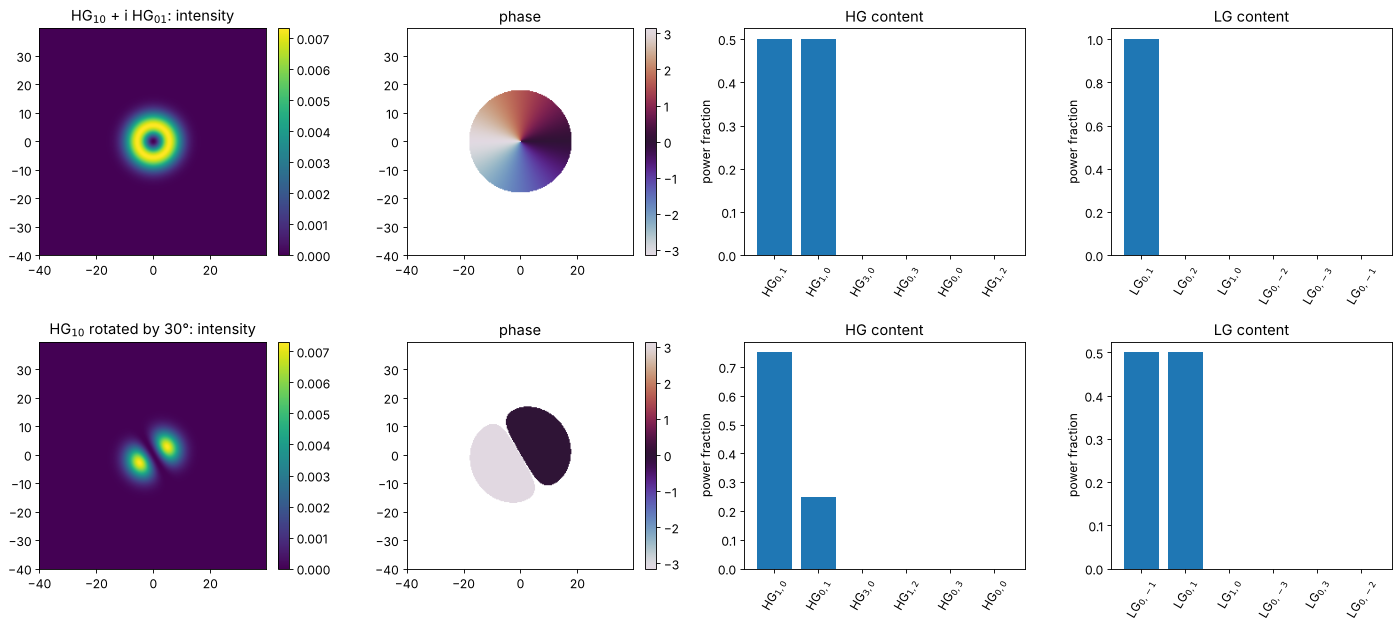

In [2]:
wl = 1.0
x, y, X, Y = grid2d(-40, 40, -40, 40, 256)
extent = [x[0], x[-1], y[0], y[-1]]
w0 = 8.0

donut = modes.hg_mode(1, 0, x, y, w0, wl) + 1j*modes.hg_mode(0, 1, x, y, w0, wl)
# HG_10 rotated by 30 degrees: cos(30) HG_10 + sin(30) HG_01
rotated = np.cos(np.pi/6)*modes.hg_mode(1, 0, x, y, w0, wl) + np.sin(np.pi/6)*modes.hg_mode(0, 1, x, y, w0, wl)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for row, (field, name) in enumerate([(donut, "HG$_{10}$ + i HG$_{01}$"), (rotated, "HG$_{10}$ rotated by 30°")]):
    show(axes[row, 0], np.abs(field)**2, name + ": intensity", extent)
    show_phase(axes[row, 1], field, "phase", extent)
    bars(axes[row, 2], modes.decompose_hg(field, x, y, w0, wl, max_order=3), 6, "HG content")
    bars(axes[row, 3], modes.decompose_lg(field, x, y, w0, wl, max_order=3), 6, "LG content")
plt.tight_layout()

### A real beam: a clipped Gaussian

A Gaussian beam with radius $w$ that passes a circular aperture of radius
$a = w$ loses $e^{-2} \approx 13.5\,\%$ of its power and gets hard edges. Its
mode content spreads over many radially symmetric modes: only LG$_{p0}$
modes (and the HG combinations $l, m$ even) appear. The figure shows the
power per mode order and how the captured power and the rms reconstruction
error $\lVert E - \sum_j c_j u_j\rVert / \lVert E \rVert$ evolve with
`max_order`.

power in LG_00: 0.8650 (analytic 1 - exp(-2) = 0.8647)


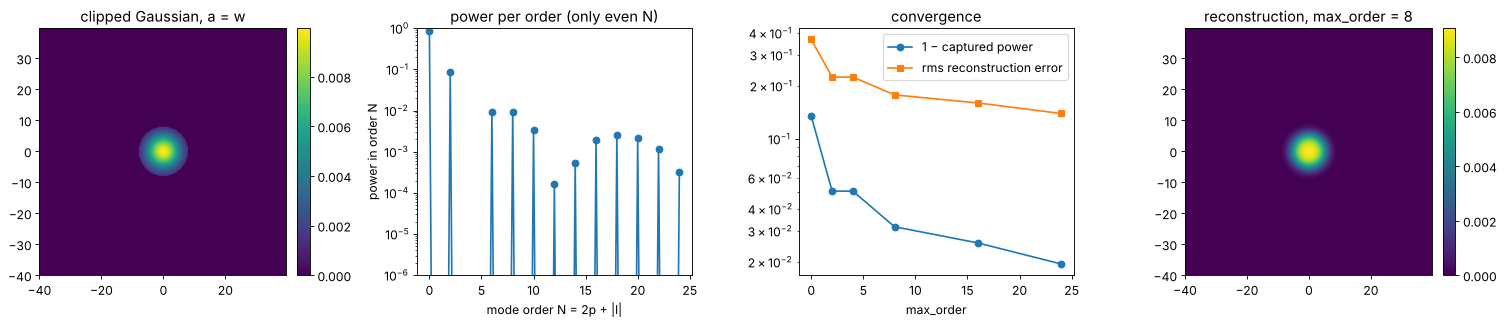

In [3]:
w = 8.0
aperture = X**2 + Y**2 <= w**2
clipped = modes.hg_mode(0, 0, x, y, w, wl)*aperture

orders = [0, 2, 4, 8, 16, 24]
results = [modes.decompose_lg(clipped, x, y, w, wl, max_order=N) for N in orders]

fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
show(axes[0], np.abs(clipped)**2, "clipped Gaussian, a = w", extent)
d = results[-1]
axes[1].semilogy(d.order_fractions(), "o-")
axes[1].set_xlabel("mode order N = 2p + |l|"); axes[1].set_ylabel("power in order N")
axes[1].set_title("power per order (only even N)")
axes[1].set_ylim(1E-6, 1)
axes[2].plot(orders, [1 - r.captured_power for r in results], "o-", label="1 − captured power")
axes[2].plot(orders, [r.reconstruction_error for r in results], "s-", label="rms reconstruction error")
axes[2].set_yscale("log"); axes[2].set_xlabel("max_order"); axes[2].legend(); axes[2].set_title("convergence")
r8 = results[3]
show(axes[3], np.abs(r8.reconstruct(x, y))**2, "reconstruction, max_order = 8", extent)
plt.tight_layout()
print("power in LG_00: {:.4f} (analytic 1 - exp(-2) = {:.4f})".format(d.power_fractions[(0, 0)], 1 - np.exp(-2)))

The convergence is slow, as for any field with a hard edge: the error falls
roughly like a power of the order, not exponentially. The power in
LG$_{00}$ is the overlap of the clipped beam with the original Gaussian:
the overlap integral is the transmitted power $1 - e^{-2}$, and normalized
by that power, the fraction in LG$_{00}$ is again $1 - e^{-2}$.

### The basis waist matters

Any $w_0$ gives a complete basis, but a basis that is too narrow or too wide
needs many more modes to describe the same beam. Below, a beam that consists
of a few modes of waist 8 µm, observed 300 µm behind its waist, is
decomposed in bases with different $w_0$ (and the correct $z$). With
`w0=None`, `fit_basis()` finds the basis that captures the most power with
the given `max_order`, starting from the second moments and the phase
curvature of the field.

fitted basis: w0 = 8.0000 µm, z = 300.000 µm (true 8, 300); captured power 1.6e-15 short of 1


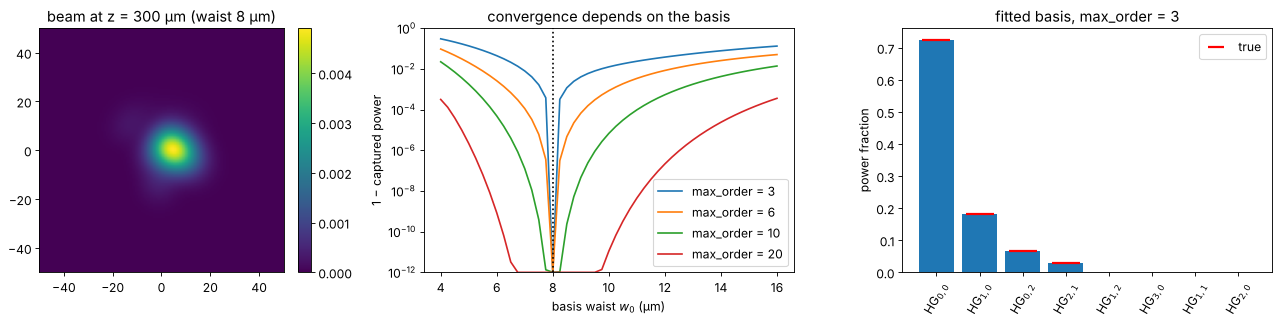

In [4]:
# a larger window: wide bases with many modes must fit on the grid
xb, yb, _, _ = grid2d(-100, 100, -100, 100, 320)
z = 300.0
coeffs = {(0, 0): 1.0, (1, 0): 0.5j, (0, 2): 0.3, (2, 1): 0.2*np.exp(1j)}
beam = sum(c*modes.hg_mode(*key, xb, yb, 8.0, wl, z) for key, c in coeffs.items())

w0_values = np.linspace(4, 16, 49)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
show(axes[0], np.abs(beam)**2, "beam at z = 300 µm (waist 8 µm)", [xb[0], xb[-1], yb[0], yb[-1]])
axes[0].set_xlim(-50, 50); axes[0].set_ylim(-50, 50)
for N in (3, 6, 10, 20):
    lost = [1 - modes.decompose_hg(beam, xb, yb, w0_b, wl, z, max_order=N).captured_power for w0_b in w0_values]
    axes[1].semilogy(w0_values, np.maximum(lost, 1E-12), label=f"max_order = {N}")
axes[1].set_ylim(1E-12, 1)
axes[1].axvline(8.0, color="k", ls=":")
axes[1].set_xlabel("basis waist $w_0$ (µm)"); axes[1].set_ylabel("1 − captured power"); axes[1].legend()
axes[1].set_title("convergence depends on the basis")

fit = modes.decompose_hg(beam, xb, yb, wavelength=wl, max_order=3)
print("fitted basis: w0 = {:.4f} µm, z = {:.3f} µm (true 8, 300); captured power {:.1e} short of 1".format(
      fit.basis.w0, fit.basis.z, abs(1 - fit.captured_power)))
bars(axes[2], fit, 8, "fitted basis, max_order = 3")
for i, (key, f) in enumerate(sorted(fit.power_fractions.items(), key=lambda kv: -kv[1])[:4]):
    axes[2].plot(i, abs(coeffs[key])**2/sum(abs(c)**2 for c in coeffs.values()), "r_", ms=25, mew=2)
axes[2].plot([], [], "r_", ms=15, mew=2, label="true"); axes[2].legend()
plt.tight_layout()

## 2. A spiral phase plate

A spiral phase plate imprints $e^{i\varphi}$ on a Gaussian beam. The result
has a phase singularity but no dark core yet: it is not the donut mode
LG$_{01}$. Only modes with $l = 1$ occur, and with the basis waist equal to
the beam radius, the projection onto LG$_{p1}$ can be done analytically
(with $t = 2r^2/w^2$ and $\int_0^\infty t^{1/2} L_p^1(t) e^{-t} dt =
\Gamma(3/2)\Gamma(p + 1/2)/(p!\,\Gamma(1/2)) = \Gamma(p + 1/2)/(2\,p!)$):

$$
|c_p|^2 = \frac{\Gamma(p + 1/2)^2}{4\,(p!)^2\,(p + 1)},
\qquad |c_0|^2 = \frac{\pi}{4}.
$$

Only 78.5 % of the power ends up in the donut mode. The rest goes into
radial modes $p \ge 1$, which form the faint outer rings after propagation.
`ModeDecomposition.propagate(dz)` gives the expansion in another plane: the
coefficients stay the same, only the basis moves.

LG_01: numeric 0.78538, analytic pi/4 = 0.78540
largest |l| != 1 power: 9.5e-07


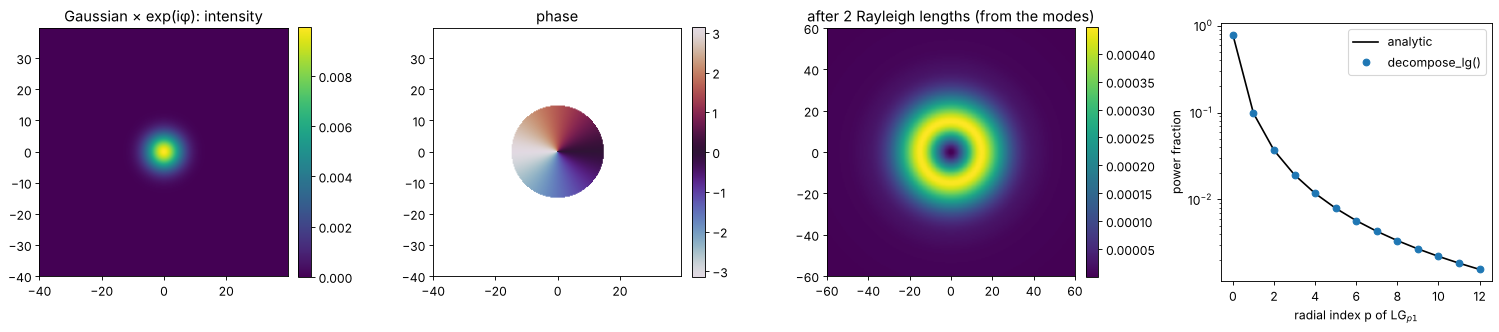

In [5]:
w = 8.0
spiral = modes.hg_mode(0, 0, x, y, w, wl)*np.exp(1j*np.arctan2(Y, X))
d = modes.decompose_lg(spiral, x, y, w, wl, max_order=25)

p = list(range(13))
analytic = [gamma(n + 0.5)**2/(4*factorial(n)**2*(n + 1)) for n in p]
numeric = [d.power_fractions[(n, 1)] for n in p]

# the expansion propagates by changing the basis only (Gouy phases are in the modes):
xp, yp, _, _ = grid2d(-80, 80, -80, 80, 256)
far = d.propagate(2*pi*w**2/wl).reconstruct(xp, yp)   # two Rayleigh lengths

fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
show(axes[0], np.abs(spiral)**2, "Gaussian × exp(iφ): intensity", extent)
show_phase(axes[1], spiral, "phase", extent)
show(axes[2], np.abs(far)**2, "after 2 Rayleigh lengths (from the modes)", [xp[0], xp[-1], yp[0], yp[-1]])
axes[2].set_xlim(-60, 60); axes[2].set_ylim(-60, 60)
axes[3].semilogy(p, analytic, "k-", label="analytic")
axes[3].semilogy(p, numeric, "o", label="decompose_lg()")
axes[3].set_xlabel("radial index p of LG$_{p1}$"); axes[3].set_ylabel("power fraction"); axes[3].legend()
plt.tight_layout()
print("LG_01: numeric {:.5f}, analytic pi/4 = {:.5f}".format(numeric[0], pi/4))
print("largest |l| != 1 power: {:.1e}".format(max(f for (pp, l), f in d.power_fractions.items() if l != 1)))

The small deviations at large $p$ come from sampling the phase singularity
at the centre (and from the truncation: the modes beyond `max_order` hold the
last few per cent of the power, because the singular phase decays only
slowly in the LG$_{p1}$ spectrum).

## 3. M² from the mode content

The Hermite functions are the eigenstates of the quantum harmonic
oscillator. With $\xi = \sqrt{2}x/w_0$, position and direction are
$\xi = (a + a^\dagger)/\sqrt{2}$ and $p = i(a^\dagger - a)/\sqrt{2}$ in terms
of the ladder operators, so the second moments of any coherent superposition
follow from sums over the HG coefficients, and

$$
M_x^2 = 2\sqrt{\operatorname{Var}\xi\,\operatorname{Var}p - \operatorname{Cov}(\xi, p)^2}.
$$

For a pure mode, $M_x^2 = 2l + 1$. For a superposition, the cross terms
matter: an incoherent mixture of the same modes would give
$\sum_j P_j(2l_j + 1)/P$. `ModeDecomposition.M2()` evaluates the formula (an
LG decomposition is converted to HG first).

First test: a coherent mixture of HG$_{00}$, HG$_{10}$, HG$_{20}$ and
HG$_{02}$ with different phases, a "multimode laser" whose centroid wanders
and whose widths change differently from a Gaussian beam along $z$. The
mode content is evaluated in one plane and compared with an ISO 11146
measurement: second moment widths at 21 planes, fitted with
`beam_quality.fit_caustic()`.

fitted basis: w0 = 10.0000 µm, z/z_R = 0.3000
M² from the mode content:  x 1.7229, y 1.2022  (incoherent mixture: x 1.9718)


M² from the caustic fit:   x 1.7229, y 1.2022


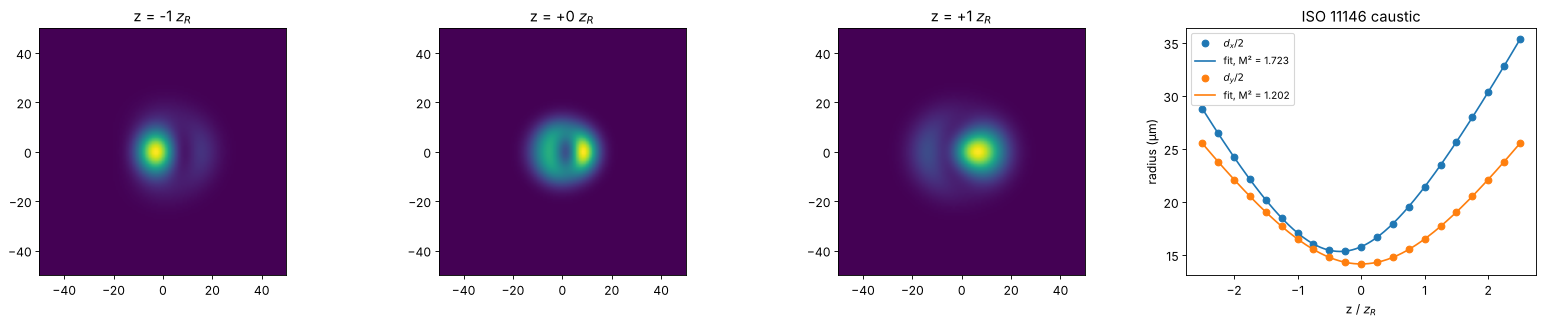

In [6]:
x2, y2, X2, Y2 = grid2d(-150, 150, -150, 150, 512)
ext2 = [x2[0], x2[-1], y2[0], y2[-1]]
w0 = 10.0
z_R = np.pi*w0**2/wl
c = {(0, 0): 1.0, (1, 0): 0.6j, (2, 0): 0.5*np.exp(0.7j), (0, 2): 0.4}


def laser(z):
    return sum(ci*modes.hg_mode(*key, x2, y2, w0, wl, z) for key, ci in c.items())


d = modes.decompose_hg(laser(0.3*z_R), x2, y2, wavelength=wl, max_order=4)
M2_x, M2_y = d.M2()
P = sum(abs(ci)**2 for ci in c.values())
incoherent_x = sum(abs(ci)**2*(2*l + 1) for (l, m), ci in c.items())/P
print("fitted basis: w0 = {:.4f} µm, z/z_R = {:.4f}".format(d.basis.w0, d.basis.z/z_R))
print("M² from the mode content:  x {:.4f}, y {:.4f}  (incoherent mixture: x {:.4f})".format(M2_x, M2_y, incoherent_x))

zs = np.linspace(-2.5*z_R, 2.5*z_R, 21)
widths = [beam_widths(np.abs(laser(z))**2, x2, y2, iterate=False) for z in zs]
d_x = np.array([wd.d_x if abs(wd.phi) < np.pi/8 else wd.d_y for wd in widths])
d_y = np.array([wd.d_y if abs(wd.phi) < np.pi/8 else wd.d_x for wd in widths])
fits = fit_caustic(zs, d_x, wl), fit_caustic(zs, d_y, wl)
print("M² from the caustic fit:   x {:.4f}, y {:.4f}".format(fits[0].M2, fits[1].M2))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
for ax, z in zip(axes[:3], (-z_R, 0, z_R)):
    show(ax, np.abs(laser(z))**2, f"z = {z/z_R:+.0f} $z_R$", ext2, colorbar=False)
    ax.set_xlim(-50, 50); ax.set_ylim(-50, 50)
zz = np.linspace(zs[0], zs[-1], 200)
for dd, fit, name in ((d_x, fits[0], "x"), (d_y, fits[1], "y")):
    line, = axes[3].plot(zs/z_R, dd/2, "o", label=f"$d_{name}/2$")
    axes[3].plot(zz/z_R, np.sqrt(fit.d_0**2 + fit.theta**2*(zz - fit.z_0)**2)/2, "-", color=line.get_color(),
                 label=f"fit, M² = {fit.M2:.3f}")
axes[3].set_xlabel("z / $z_R$"); axes[3].set_ylabel("radius (µm)"); axes[3].legend(fontsize=9)
axes[3].set_title("ISO 11146 caustic")
plt.tight_layout()

The mode content gives the ISO M² exactly, and different from the
incoherent mixture: the phases between modes of the same parity matter.

### Truncation and M²

M² is a second moment, and the far wings of the angular spectrum weigh
heavily. A Gaussian beam with spherical aberration, phase $0.3\pi\,(r/w)^4$,
has its mode content spread over many orders. With growing `max_order`,
the M² of the expansion converges (from below) to the exact second moment
value, here computed from radial integrals of the amplitude $A$ and the
phase gradient,
$\langle\theta_x^2\rangle = \int(|\nabla A|^2 + A^2|\nabla\varphi|^2)/(2k^2P)$.
Even when 99.99 % of the power is captured, M² can still be a few per cent
low. (The basis is fitted anew for each `max_order`.)

max_order  2: captured power 0.976659, M² = 1.2528
max_order  4: captured power 0.983103, M² = 1.3047
max_order  8: captured power 0.997137, M² = 1.5210
max_order 12: captured power 0.999208, M² = 1.5983
max_order 16: captured power 0.999721, M² = 1.6313
max_order 24: captured power 0.999955, M² = 1.6560
max_order 32: captured power 0.999991, M² = 1.6630


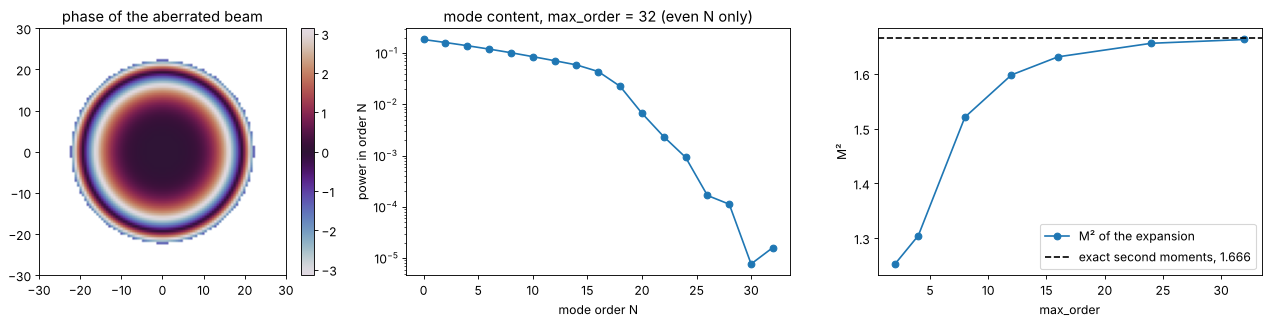

In [7]:
w = 12.0
alpha = 0.3*np.pi
aberrated = modes.hg_mode(0, 0, x2, y2, w, wl)*np.exp(1j*alpha*((X2**2 + Y2**2)/w**2)**2)

# exact second moments (rotationally symmetric, per axis half of the radial moments):
k = 2*np.pi/wl
A = lambda r: np.exp(-r**2/w**2)
dphi = lambda r: 4*alpha*r**3/w**4
P = quad(lambda r: A(r)**2*r, 0, np.inf)[0]
x2_mean = quad(lambda r: A(r)**2*r**3, 0, np.inf)[0]/(2*P)
th2_mean = quad(lambda r: ((2*r/w**2*A(r))**2 + A(r)**2*dphi(r)**2)*r, 0, np.inf)[0]/(2*P*k**2)
xth_mean = quad(lambda r: A(r)**2*r**2*dphi(r), 0, np.inf)[0]/(2*P*k)
M2_exact = 2*k*np.sqrt(x2_mean*th2_mean - xth_mean**2)

orders = [2, 4, 8, 12, 16, 24, 32]
# a basis fitted for each max_order:
results = [modes.decompose_hg(aberrated, x2, y2, wavelength=wl, max_order=N) for N in orders]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
show_phase(axes[0], aberrated, "phase of the aberrated beam", ext2)
axes[0].set_xlim(-30, 30); axes[0].set_ylim(-30, 30)
axes[1].semilogy(np.arange(0, orders[-1] + 1, 2), results[-1].order_fractions()[::2], "o-")
axes[1].set_xlabel("mode order N"); axes[1].set_ylabel("power in order N")
axes[1].set_title("mode content, max_order = 32 (even N only)")
axes[2].plot(orders, [r.M2()[0] for r in results], "o-", label="M² of the expansion")
axes[2].axhline(M2_exact, color="k", ls="--", label=f"exact second moments, {M2_exact:.3f}")
axes[2].set_xlabel("max_order"); axes[2].set_ylabel("M²"); axes[2].legend()
plt.tight_layout()
for N, r in zip(orders, results):
    print("max_order {:2d}: captured power {:.6f}, M² = {:.4f}".format(N, r.captured_power, r.M2()[0]))

## 4. LP modes of a step-index fibre

In the weakly guiding approximation ($n_\mathrm{core} - n_\mathrm{clad} \ll
n_\mathrm{core}$, true for telecom fibres with $\Delta n \approx 0.005$) the
modes are linearly polarized, $\mathrm{LP}_{lm}$, with

$$
E = \begin{cases} J_l(Ur/a)/J_l(U) & r \le a \\ K_l(Wr/a)/K_l(W) & r > a \end{cases}
\times \cos(l\varphi) \text{ or } \sin(l\varphi),
\qquad U^2 + W^2 = V^2 = \left(\frac{2\pi a}{\lambda}\mathrm{NA}\right)^2,
$$

and $U, W$ from the characteristic equation
$U J_{l-1}(U)/J_l(U) = -W K_{l-1}(W)/K_l(W)$ (continuity of the field and its
derivative at $r = a$). `lp_modes(V)` finds all guided modes, sorted by the
normalized propagation constant $b = W^2/V^2$, which gives
$n_\mathrm{eff}^2 = n_\mathrm{clad}^2 + b\,(n_\mathrm{core}^2 -
n_\mathrm{clad}^2)$. A mode is cut off where $W \to 0$, at the zeros of
$J_{l-1}$: the fibre is single mode below $V = 2.405$. Vectorial effects
(the splitting of LP modes into HE, EH, TE and TM modes) are not modelled.

LP01 b(V) against the approximation b = (1.1428 - 0.996/V)**2 (Rudolph and Neumann):
  V = 1.500: b = 0.2292, approximation 0.2292
  V = 2.000: b = 0.4162, approximation 0.4158
  V = 2.405: b = 0.5313, approximation 0.5309


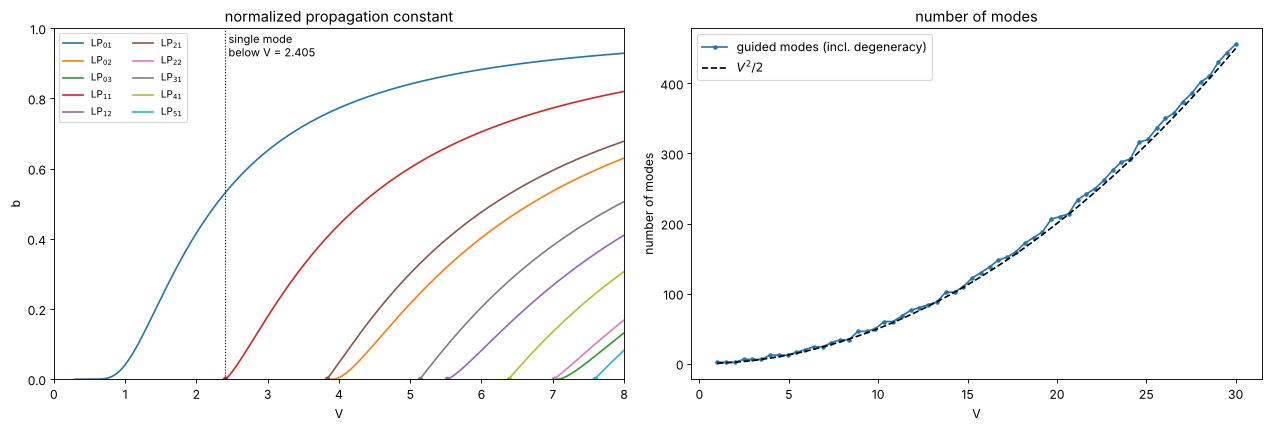

In [8]:
V_values = np.linspace(0.3, 8, 300)
curves = {}
for V in V_values:
    for mode in modes.lp_modes(V):
        curves.setdefault((mode.l, mode.m), []).append((V, mode.b))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for (l, m), points in sorted(curves.items()):
    V_c = modes.lp_cutoff(l, m)
    Vb = np.array([(V_c, 0.0)] + points) if V_c > 0 else np.array(points)
    line, = axes[0].plot(Vb[:, 0], Vb[:, 1], label=f"LP$_{{{l}{m}}}$")
    if V_c > 0:
        axes[0].plot(V_c, 0, "o", color=line.get_color(), ms=4)
axes[0].axvline(2.405, color="k", ls=":", lw=1)
axes[0].text(2.45, 0.92, "single mode\nbelow V = 2.405", fontsize=10)
axes[0].set_xlabel("V"); axes[0].set_ylabel("b"); axes[0].set_ylim(0, 1); axes[0].set_xlim(0, 8)
axes[0].legend(ncol=2, fontsize=9); axes[0].set_title("normalized propagation constant")

V_many = np.linspace(1, 30, 60)
count = [sum(mode.degeneracy for mode in modes.lp_modes(V)) for V in V_many]
axes[1].plot(V_many, count, "o-", ms=3, label="guided modes (incl. degeneracy)")
axes[1].plot(V_many, V_many**2/2, "k--", label="$V^2/2$")
axes[1].set_xlabel("V"); axes[1].set_ylabel("number of modes"); axes[1].legend()
axes[1].set_title("number of modes")
plt.tight_layout()

print("LP01 b(V) against the approximation b = (1.1428 - 0.996/V)**2 (Rudolph and Neumann):")
for V in (1.5, 2.0, 2.405):
    print("  V = {:.3f}: b = {:.4f}, approximation {:.4f}".format(V, modes.lp_mode(0, 1, V).b, (1.1428 - 0.996/V)**2))

The mode fields of a fibre with $V = 6$ (core radius 5 µm). Modes with
$l \ge 1$ come in a $\cos(l\varphi)$ and a $\sin(l\varphi)$ version (plus two
polarizations each); their sum with a phase of 90° is a helical mode
$e^{\pm il\varphi}$ (`orientation="+"` or `"-"`).

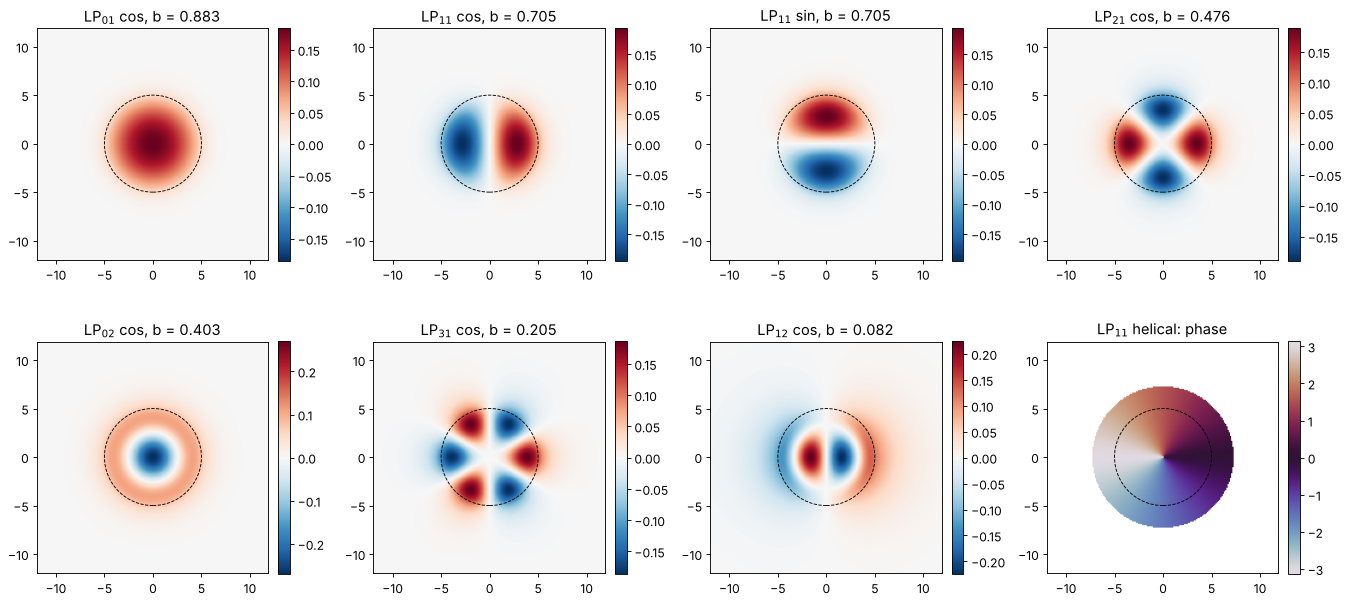

In [9]:
a = 5.0
xf, yf, Xf, Yf = grid2d(-12, 12, -12, 12, 192)
ext_f = [xf[0], xf[-1], yf[0], yf[-1]]
lp = modes.lp_modes(6.0)
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
entries = [(lp[0], "cos"), (lp[1], "cos"), (lp[1], "sin"), (lp[2], "cos"),
           (lp[3], "cos"), (lp[4], "cos"), (lp[5], "cos"), (lp[1], "+")]
for ax, (mode, orientation) in zip(axes.ravel(), entries):
    field = mode.field(xf, yf, a, orientation)
    if orientation == "+":
        show_phase(ax, field, f"LP$_{{{mode.l}{mode.m}}}$ helical: phase", ext_f)
    else:
        lim = np.abs(field).max()
        show(ax, field.real, f"LP$_{{{mode.l}{mode.m}}}$ {orientation}, b = {mode.b:.3f}", ext_f,
             cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.add_patch(plt.Circle((0, 0), a, fill=False, color="k", ls="--", lw=0.8))
plt.tight_layout()

### Marcuse's Gaussian approximation

The fundamental mode LP01 looks Gaussian. Marcuse fitted the radius of the
best matching Gaussian,

$$
\frac{w}{a} = 0.65 + \frac{1.619}{V^{3/2}} + \frac{2.879}{V^6},
$$

which is accurate to better than 1 % for $1.2 < V < 2.4$
(`marcuse_mode_field_radius()`; the mode field diameter is $2w$). Below it
is compared with the exact best fit (maximum overlap with LP01, from radial
integrals). The overlap of the best Gaussian with LP01 exceeds 99 % for
$V > 2$: for single mode fibres, Gaussian beam optics (`abcd`) is an
excellent model. Close to $V = 1$, LP01 extends far into the cladding with
the slowly decaying $K_0$ tail, and the Gaussian is a poor fit.

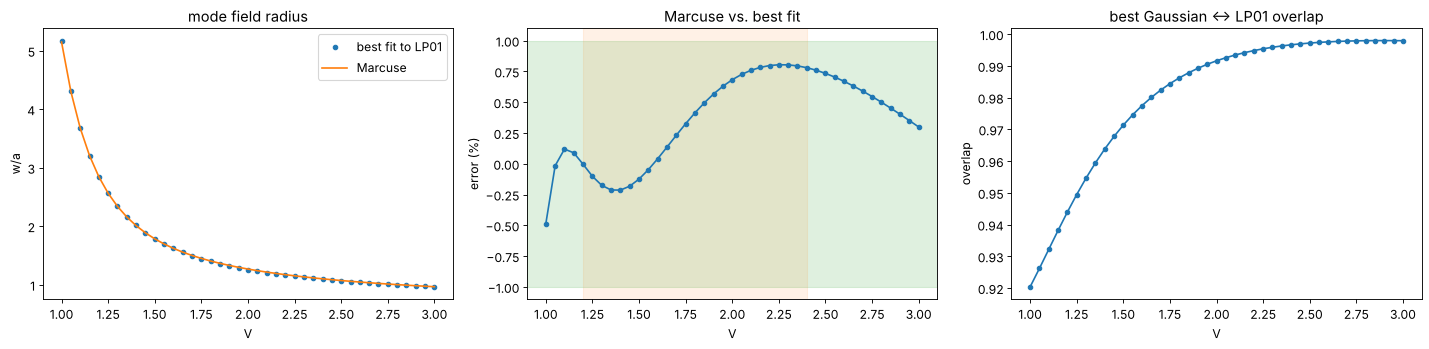

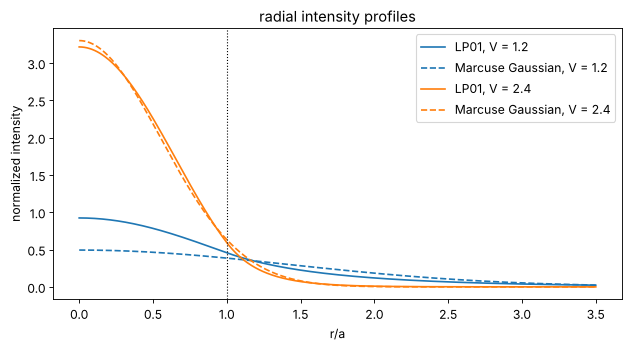

In [10]:
def radial_overlap(mode, w, a=1.0):
    f = lambda r: mode.radial(r, a)
    integrate = lambda g: quad(g, 0, a)[0] + quad(g, a, np.inf)[0]
    num = integrate(lambda r: f(r)*np.exp(-r**2/w**2)*r)
    return num**2/(integrate(lambda r: f(r)**2*r)*w**2/4)


V_values = np.linspace(1.0, 3.0, 41)
best_w, best_eta = [], []
for V in V_values:
    mode = modes.lp_mode(0, 1, V)
    res = minimize_scalar(lambda w: -radial_overlap(mode, w), bounds=(0.3, 10), method="bounded",
                          options={"xatol": 1E-10})
    best_w.append(res.x); best_eta.append(-res.fun)
best_w = np.array(best_w)
marcuse = modes.marcuse_mode_field_radius(V_values, 1.0)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(V_values, best_w, "o", ms=4, label="best fit to LP01")
axes[0].plot(V_values, marcuse, "-", label="Marcuse")
axes[0].set_xlabel("V"); axes[0].set_ylabel("w/a"); axes[0].legend(); axes[0].set_title("mode field radius")
axes[1].plot(V_values, 100*(marcuse/best_w - 1), "o-", ms=4)
axes[1].axhspan(-1, 1, color="C2", alpha=0.15); axes[1].axvspan(1.2, 2.4, color="C1", alpha=0.1)
axes[1].set_xlabel("V"); axes[1].set_ylabel("error (%)"); axes[1].set_title("Marcuse vs. best fit")
axes[2].plot(V_values, best_eta, "o-", ms=4)
axes[2].set_xlabel("V"); axes[2].set_ylabel("overlap"); axes[2].set_title("best Gaussian ↔ LP01 overlap")
plt.tight_layout()

fig, ax = plt.subplots(figsize=(8, 4.5))
r = np.linspace(0, 3.5, 400)
for V, color in ((1.2, "C0"), (2.4, "C1")):
    mode = modes.lp_mode(0, 1, V)
    w_m = modes.marcuse_mode_field_radius(V, 1.0)
    # scale the Gaussian for maximum overlap (same normalization as the radial overlap):
    norm = quad(lambda s: mode.radial(s, 1)**2*s, 0, np.inf, limit=200)[0]
    ax.plot(r, mode.radial(r, 1)**2/norm, color=color, label=f"LP01, V = {V}")
    ax.plot(r, np.exp(-2*r**2/w_m**2)/(w_m**2/4), "--", color=color, label=f"Marcuse Gaussian, V = {V}")
ax.axvline(1, color="k", ls=":", lw=1)
ax.set_xlabel("r/a"); ax.set_ylabel("normalized intensity"); ax.legend(); ax.set_title("radial intensity profiles")
plt.tight_layout()

## 5. Coupling into a single mode fibre

`coupling_efficiency(field, mode, x, y)` is the normalized overlap
$\eta = |\langle u|E\rangle|^2/(\langle u|u\rangle\langle E|E\rangle)$ of any
field with any mode. `abcd.coupling_efficiency(q1, q2)` gives the same for
two Gaussian beams. Here the target is the exact LP01 mode of a fibre similar
to SMF-28 at 1550 nm (core radius 4.1 µm, NA 0.14, V = 2.33), and the beam
is a Gaussian with radius $w$ at its waist on the fibre end face.

The Gaussian model (Marcuse radius and the ABCD formula) predicts the curves
for the beam waist, a lateral offset $d$, a tilt $\theta$ and a defocus
$\Delta z$ very well:

$$
\eta_\mathrm{offset} = \eta_0\,e^{-d^2/w^2}, \qquad
\eta_\mathrm{tilt} = \eta_0\,e^{-(\pi n w \theta/\lambda)^2}
\qquad (\text{matched } w),
$$

but the maximum is $\eta_0 \approx 99.6\,\%$, not 100 %: LP01 is not exactly
Gaussian.

V = 2.327, n_eff = 1.44747, Marcuse MFD = 9.22 µm


coupling of a Gaussian with the Marcuse waist into LP01: 0.9960


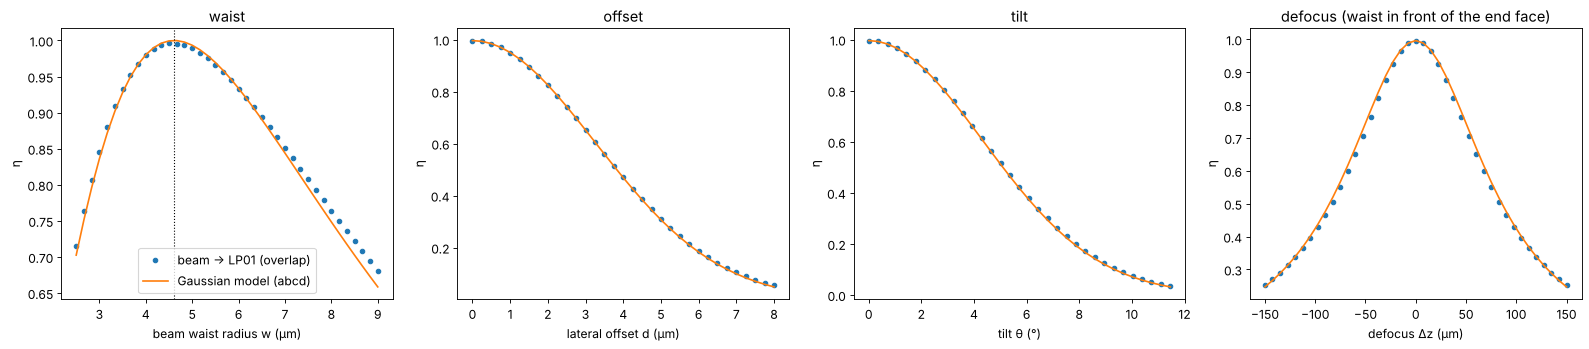

In [11]:
wl_t = 1.55
a, NA, n_clad = 4.1, 0.14, 1.444
n_core = np.sqrt(n_clad**2 + NA**2)
lp01 = modes.lp_modes(core_radius=a, n_core=n_core, n_clad=n_clad, wavelength=wl_t)[0]
V = lp01.V
w_m = modes.marcuse_mode_field_radius(V, a)
print("V = {:.3f}, n_eff = {:.5f}, Marcuse MFD = {:.2f} µm".format(V, lp01.n_eff, 2*w_m))

xs, ys, Xs, Ys = grid2d(-40, 40, -40, 40, 256)
mode = lp01.field(xs, ys, a)
q_fibre = 1j*np.pi*w_m**2/wl_t

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
w_values = np.linspace(2.5, 9, 40)
eta_w = [modes.coupling_efficiency(modes.hg_mode(0, 0, xs, ys, w_b, wl_t), mode, xs, ys) for w_b in w_values]
axes[0].plot(w_values, eta_w, "o", ms=4, label="beam → LP01 (overlap)")
axes[0].plot(w_values, [abcd.coupling_efficiency(1j*np.pi*w_b**2/wl_t, q_fibre, wl_t) for w_b in w_values], "-",
             label="Gaussian model (abcd)")
axes[0].axvline(w_m, color="k", ls=":", lw=1)
axes[0].set_xlabel("beam waist radius w (µm)"); axes[0].set_ylabel("η"); axes[0].legend(); axes[0].set_title("waist")

beam = modes.hg_mode(0, 0, xs, ys, w_m, wl_t)
eta0 = modes.coupling_efficiency(beam, mode, xs, ys)
offsets = np.linspace(0, 8, 33)
axes[1].plot(offsets, modes.coupling_vs_offset(beam, mode, xs, ys, offsets), "o", ms=4)
axes[1].plot(offsets, eta0*np.exp(-offsets**2/w_m**2), "-")
axes[1].set_xlabel("lateral offset d (µm)"); axes[1].set_title("offset")

angles = np.linspace(0, 0.2, 33)
axes[2].plot(np.degrees(angles), modes.coupling_vs_tilt(beam, mode, xs, ys, wl_t, angles), "o", ms=4)
axes[2].plot(np.degrees(angles), eta0*np.exp(-(np.pi*w_m*np.sin(angles)/wl_t)**2), "-")
axes[2].set_xlabel("tilt θ (°)"); axes[2].set_title("tilt")

dz = np.linspace(-150, 150, 41)
axes[3].plot(dz, modes.coupling_vs_defocus(beam, mode, xs, ys, wl_t, dz), "o", ms=4)
axes[3].plot(dz, [eta0*abcd.coupling_efficiency(q_fibre + d, q_fibre, wl_t) for d in dz], "-")
axes[3].set_xlabel("defocus Δz (µm)"); axes[3].set_title("defocus (waist in front of the end face)")
for ax in axes[1:]:
    ax.set_ylabel("η")
plt.tight_layout()
print("coupling of a Gaussian with the Marcuse waist into LP01: {:.4f}".format(eta0))

### Aberrated beams

The overlap integral handles any field. A beam focused onto the fibre with
spherical aberration, phase $2\pi\,c\,(6\rho^4 - 6\rho^2 + 1)$ with
$\rho = r/(2w)$, couples worse. Moving the fibre along $z$ partly
compensates the aberration: the best focus shifts, and the loss at best
focus is smaller.

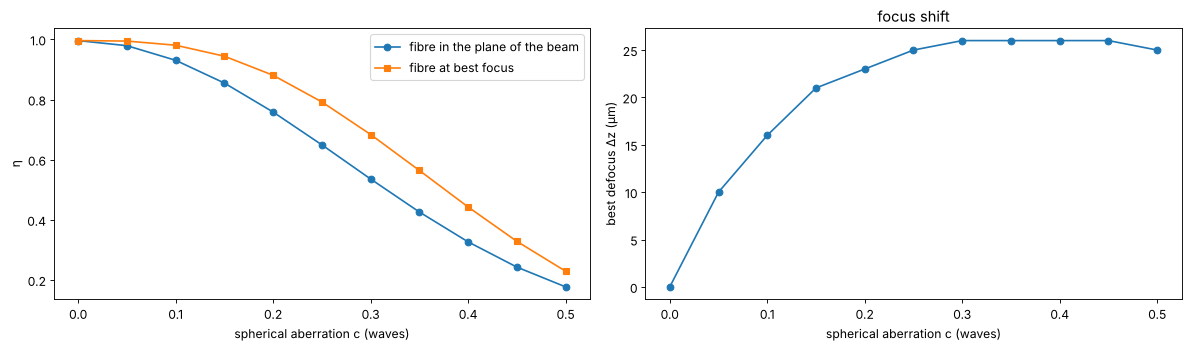

In [12]:
rho2 = (Xs**2 + Ys**2)/(2*w_m)**2
coeffs_sa = np.linspace(0, 0.5, 11)
dz_search = np.linspace(-40, 40, 81)
eta_sa, eta_best, dz_best = [], [], []
for c in coeffs_sa:
    field = beam*np.exp(2j*np.pi*c*(6*rho2**2 - 6*rho2 + 1))
    eta_sa.append(modes.coupling_efficiency(field, mode, xs, ys))
    sweep = modes.coupling_vs_defocus(field, mode, xs, ys, wl_t, dz_search)
    eta_best.append(sweep.max()); dz_best.append(dz_search[sweep.argmax()])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(coeffs_sa, eta_sa, "o-", label="fibre in the plane of the beam")
axes[0].plot(coeffs_sa, eta_best, "s-", label="fibre at best focus")
axes[0].set_xlabel("spherical aberration c (waves)"); axes[0].set_ylabel("η"); axes[0].legend()
axes[1].plot(coeffs_sa, dz_best, "o-")
axes[1].set_xlabel("spherical aberration c (waves)"); axes[1].set_ylabel("best defocus Δz (µm)")
axes[1].set_title("focus shift")
plt.tight_layout()

### Exciting higher modes in a few-mode fibre

A fibre with $V = 4.5$ guides LP01, LP11, LP21 and LP02. A Gaussian beam
matched to LP01 and shifted along $x$ excites the odd mode LP11 (cos) first,
then LP21 and LP02. `mode_power_fractions()` gives the power coupled into each
mode of a list of (orthogonal) modes; what is missing to 1 is radiated into
the cladding. The $y$-oriented modes (sin) stay dark because of the mirror
symmetry of the shifted beam about the $x$ axis.

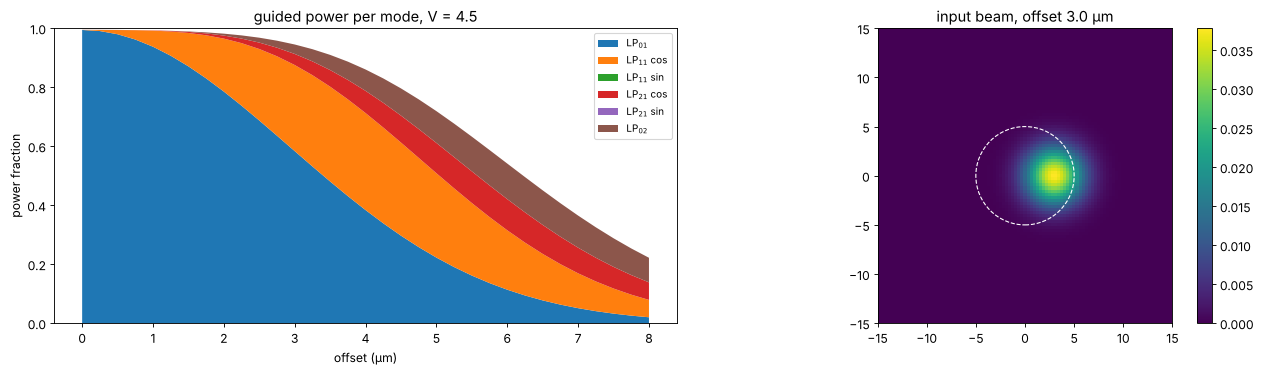

In [13]:
a_fm = 5.0
lp_fm = modes.lp_modes(4.5)
fields, labels = [], []
for m in lp_fm:
    for orientation in (["cos"] if m.l == 0 else ["cos", "sin"]):
        fields.append(m.field(xs, ys, a_fm, orientation))
        labels.append(f"LP$_{{{m.l}{m.m}}}$" + ("" if m.l == 0 else f" {orientation}"))

w_fm = modes.marcuse_mode_field_radius(lp_fm[0].V, a_fm)
shifts = np.linspace(0, 8, 33)
fractions = np.array([modes.mode_power_fractions(modes.hg_mode(0, 0, xs, ys, w_fm, wl, x0=s), fields, xs, ys)
                      for s in shifts])

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
axes[0].stackplot(shifts, fractions.T, labels=labels)
axes[0].set_xlabel("offset (µm)"); axes[0].set_ylabel("power fraction"); axes[0].set_ylim(0, 1)
axes[0].legend(loc="upper right", fontsize=9); axes[0].set_title("guided power per mode, V = 4.5")
s_show = 3.0
show(axes[1], np.abs(modes.hg_mode(0, 0, xs, ys, w_fm, wl, x0=s_show))**2, f"input beam, offset {s_show} µm",
     [xs[0], xs[-1], ys[0], ys[-1]])
axes[1].add_patch(plt.Circle((0, 0), a_fm, fill=False, color="w", ls="--"))
axes[1].set_xlim(-15, 15); axes[1].set_ylim(-15, 15)
plt.tight_layout()

## Summary

- `decompose_hg()` and `decompose_lg()` expand any field in the modes of
  `beams`; the modes are normalized on the grid, and `fit_basis()` picks a
  waist and curvature that maximize the captured power.
- `ModeDecomposition.M2()` gives the ISO 11146 M² of the (truncated)
  expansion, including the coherent cross terms, which an incoherent
  estimate misses.
- `lp_modes()` solves the characteristic equation of a weakly guiding
  step-index fibre; `lp_cutoff()`, `marcuse_mode_field_radius()` and
  `lp_mode_field()` give cutoffs, the Gaussian approximation and the fields.
- `coupling_efficiency()` and the sweeps `coupling_vs_offset()`,
  `coupling_vs_tilt()` and `coupling_vs_defocus()` generalize
  `abcd.coupling_efficiency()` to arbitrary fields and modes.